<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%208/Latihan_Praktikum_8_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 8.10 Implementasi Python — Support Vector Machine (Breast Cancer)



## Praktikum 8.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

## Praktikum 8.2 Import Dataset

In [5]:
import os
FILE = "beast_cancer.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()      # pilih file beast_cancer.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

data = pd.read_csv(FILE).drop(columns=["id", "Unnamed: 32"])
y = (data["diagnosis"] == "M").astype(int)      # M (ganas) = 1, B (jinak) = 0
X = data.drop(columns="diagnosis")
print("Ukuran data:", X.shape, "| distribusi [jinak, ganas]:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

Ukuran data: (569, 30) | distribusi [jinak, ganas]: [357 212]


## Praktikum 8.3 Preprocessing

In [6]:
# SVM sangat sensitif terhadap skala fitur,
# scaling WAJIB dilakukan
pipeline = Pipeline([("scaler", StandardScaler()), ("svm", SVC())])

## Praktikum 8.4 Training Model dengan GridSearchCV

In [7]:
param_grid = {"svm__C": [0.1, 1, 10, 100],
              "svm__gamma": [0.001, 0.01, 0.1, 1],
              "svm__kernel": ["rbf", "linear"]}
grid_search = GridSearchCV(pipeline, param_grid, cv=5,
                           scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):", round(grid_search.best_score_, 3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.964


## Praktikum 8.5 Evaluasi

In [8]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi Test:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=["Jinak (0)", "Ganas (1)"]))

Akurasi Test: 0.982
              precision    recall  f1-score   support

   Jinak (0)       0.97      1.00      0.99        72
   Ganas (1)       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Praktikum 8.6 Visualisasi

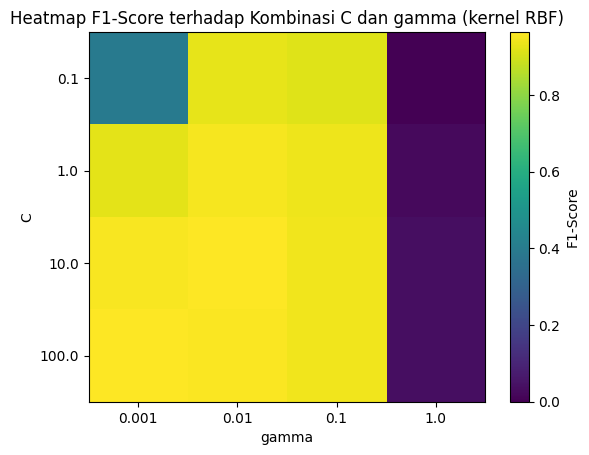

param_svm__gamma,0.001,0.010,0.100,1.000
param_svm__C,,,,
0.1,0.398,0.927,0.916,0.000
1.0,0.923,0.950,0.938,0.023
10.0,0.956,0.964,0.944,0.034
100.0,0.963,0.959,0.942,0.034


In [9]:
hasil = pd.DataFrame(grid_search.cv_results_)
hasil_rbf = hasil[hasil["param_svm__kernel"] == "rbf"]      # gamma hanya relevan untuk RBF
pivot = hasil_rbf.pivot_table(values="mean_test_score",
                              index="param_svm__C", columns="param_svm__gamma")
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("gamma"); plt.ylabel("C")
plt.title("Heatmap F1-Score terhadap Kombinasi C dan gamma (kernel RBF)")
plt.colorbar(label="F1-Score")
plt.show()
display(pivot.round(3))

### 8.10.1 Interpretasi

- **Parameter terbaik:** kernel RBF dengan C = 10 dan gamma = 0,01, dengan F1 CV = **0,964**.
- **Evaluasi test:** akurasi **0,982** (114 pasien): semua tumor jinak benar (recall 1,000) dan 40 dari 42 tumor ganas terdeteksi (recall 0,952, precision 1,000).
- **Heatmap:** "puncak" performa ada pada gamma menengah (0,001–0,1) dengan C ≥ 1 (F1 0,92–0,96). Dua wilayah buruk terlihat jelas:
  - **gamma = 1 → F1 ≈ 0 – 0,03 (overfitting):** batas keputusan terlalu rumit sehingga model menghafal data latih dan gagal pada data validasi.
  - **C = 0,1 dan gamma = 0,001 → F1 = 0,398 (underfitting):** regularisasi terlalu kuat dan kurva terlalu halus, sehingga model tidak mampu menangkap pola.
- Pola ini sesuai penjelasan buku: area performa terbaik hanya pada rentang tertentu C dan gamma, di luar itu turun karena overfitting atau underfitting.

---
## 8.11 Latihan Praktikum

### Praktikum 1: Perbandingan Kernel (Praktikum 8.7)

In [10]:
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()),
                      ("svm", SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

Kernel linear: akurasi = 0.965
Kernel poly: akurasi = 0.886
Kernel rbf: akurasi = 0.974


In [11]:
# Tambahan: F1, recall ganas, dan akurasi cross-validation agar perbandingan lebih andal
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, recall_score
skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for kernel in ["linear", "poly", "rbf"]:
    mk = lambda: Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    m = mk().fit(X_train, y_train); p = m.predict(X_test)
    rows.append({"Kernel": kernel,
                 "Akurasi test": accuracy_score(y_test, p),
                 "F1 ganas": f1_score(y_test, p),
                 "Recall ganas": recall_score(y_test, p),
                 "Akurasi CV 5-fold": cross_val_score(mk(), X, y, cv=skf, scoring="accuracy").mean()})
display(pd.DataFrame(rows).set_index("Kernel").round(3))

,Akurasi test,F1 ganas,Recall ganas,Akurasi CV 5-fold
Kernel,,,,
linear,0.965,0.950,0.905,0.974
poly,0.886,0.817,0.690,0.905
rbf,0.974,0.963,0.929,0.977


#### Kesimpulan Praktikum 1

| Kernel | Akurasi test | Akurasi CV 5-fold |
|---|---|---|
| linear | 0,965 | 0,974 |
| poly (derajat 3) | 0,886 | 0,905 |
| **rbf** | **0,974** | **0,977** |

- **RBF terbaik**, dengan Linear hampir sama. Selisih RBF dan Linear sangat kecil (1 pasien pada test set, 0,003 pada CV), sehingga keduanya praktis sebanding. Fakta bahwa kernel linear sudah sangat baik menunjukkan data ini **hampir terpisah secara linear**.
- **Polynomial paling lemah** (±0,89–0,91) pada pengaturan bawaan (derajat 3, `gamma="scale"`, `coef0=0`). Kernel ini lebih sensitif terhadap parameter dan cenderung kurang cocok bila tidak di-*tuning*; hasil ini berlaku untuk parameter bawaan, bukan batas kemampuan kernel poly.
- **Rekomendasi:** RBF (fleksibel, biasanya pilihan awal), atau Linear bila ingin model yang lebih sederhana dan cepat.

### Praktikum 2: Visualisasi Decision Boundary 2 Fitur

Fitur yang dipilih: `radius_mean` dan `texture_mean`. Model dilatih pada 2 fitur ini saja (di-scaling dalam Pipeline) agar batas keputusan bisa digambar dalam 2 dimensi. Titik bulat = data latih, segitiga = data uji.

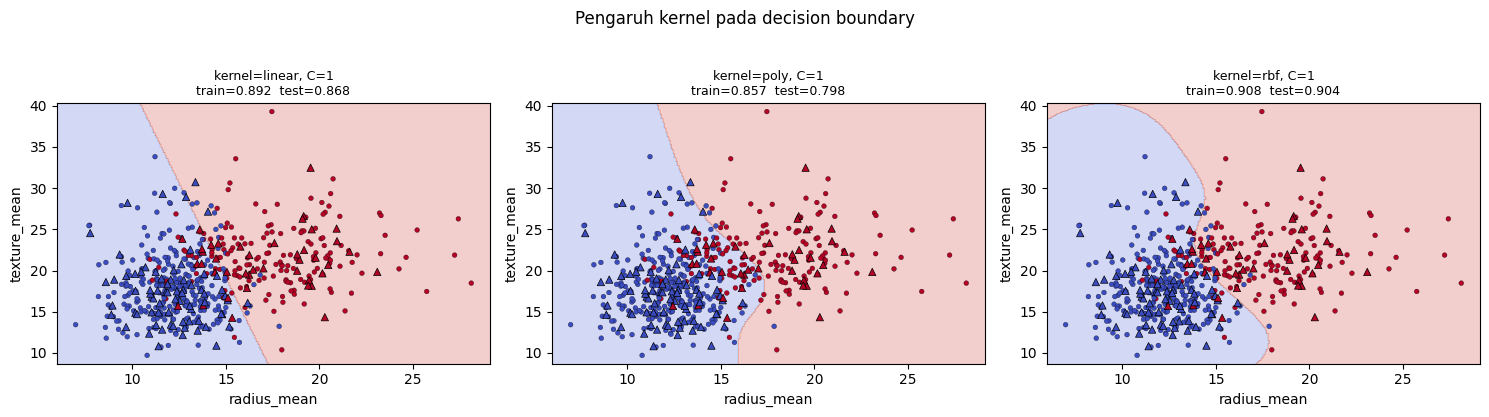

In [12]:
fitur2 = ["radius_mean", "texture_mean"]
X2 = X[fitur2]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

xx, yy = np.meshgrid(
    np.linspace(X2.iloc[:, 0].min() - 1, X2.iloc[:, 0].max() + 1, 300),
    np.linspace(X2.iloc[:, 1].min() - 1, X2.iloc[:, 1].max() + 1, 300))
grid_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=fitur2)

def plot_boundary(ax, **params):
    m = Pipeline([("scaler", StandardScaler()), ("svm", SVC(**params))]).fit(X2_train, y2_train)
    Z = m.predict(grid_df).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X2_train.iloc[:, 0], X2_train.iloc[:, 1], c=y2_train, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.2)
    ax.scatter(X2_test.iloc[:, 0], X2_test.iloc[:, 1], c=y2_test, cmap="coolwarm", s=28, marker="^", edgecolor="k", linewidth=0.5)
    tr = accuracy_score(y2_train, m.predict(X2_train)); te = accuracy_score(y2_test, m.predict(X2_test))
    ax.set_title(", ".join(f"{k}={v}" for k, v in params.items()) + f"\ntrain={tr:.3f}  test={te:.3f}", fontsize=9)
    ax.set_xlabel(fitur2[0]); ax.set_ylabel(fitur2[1])
    return tr, te

# (a) Pengaruh KERNEL (C=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, ["linear", "poly", "rbf"]):
    plot_boundary(ax, kernel=k, C=1)
plt.suptitle("Pengaruh kernel pada decision boundary", y=1.03); plt.tight_layout(); plt.show()

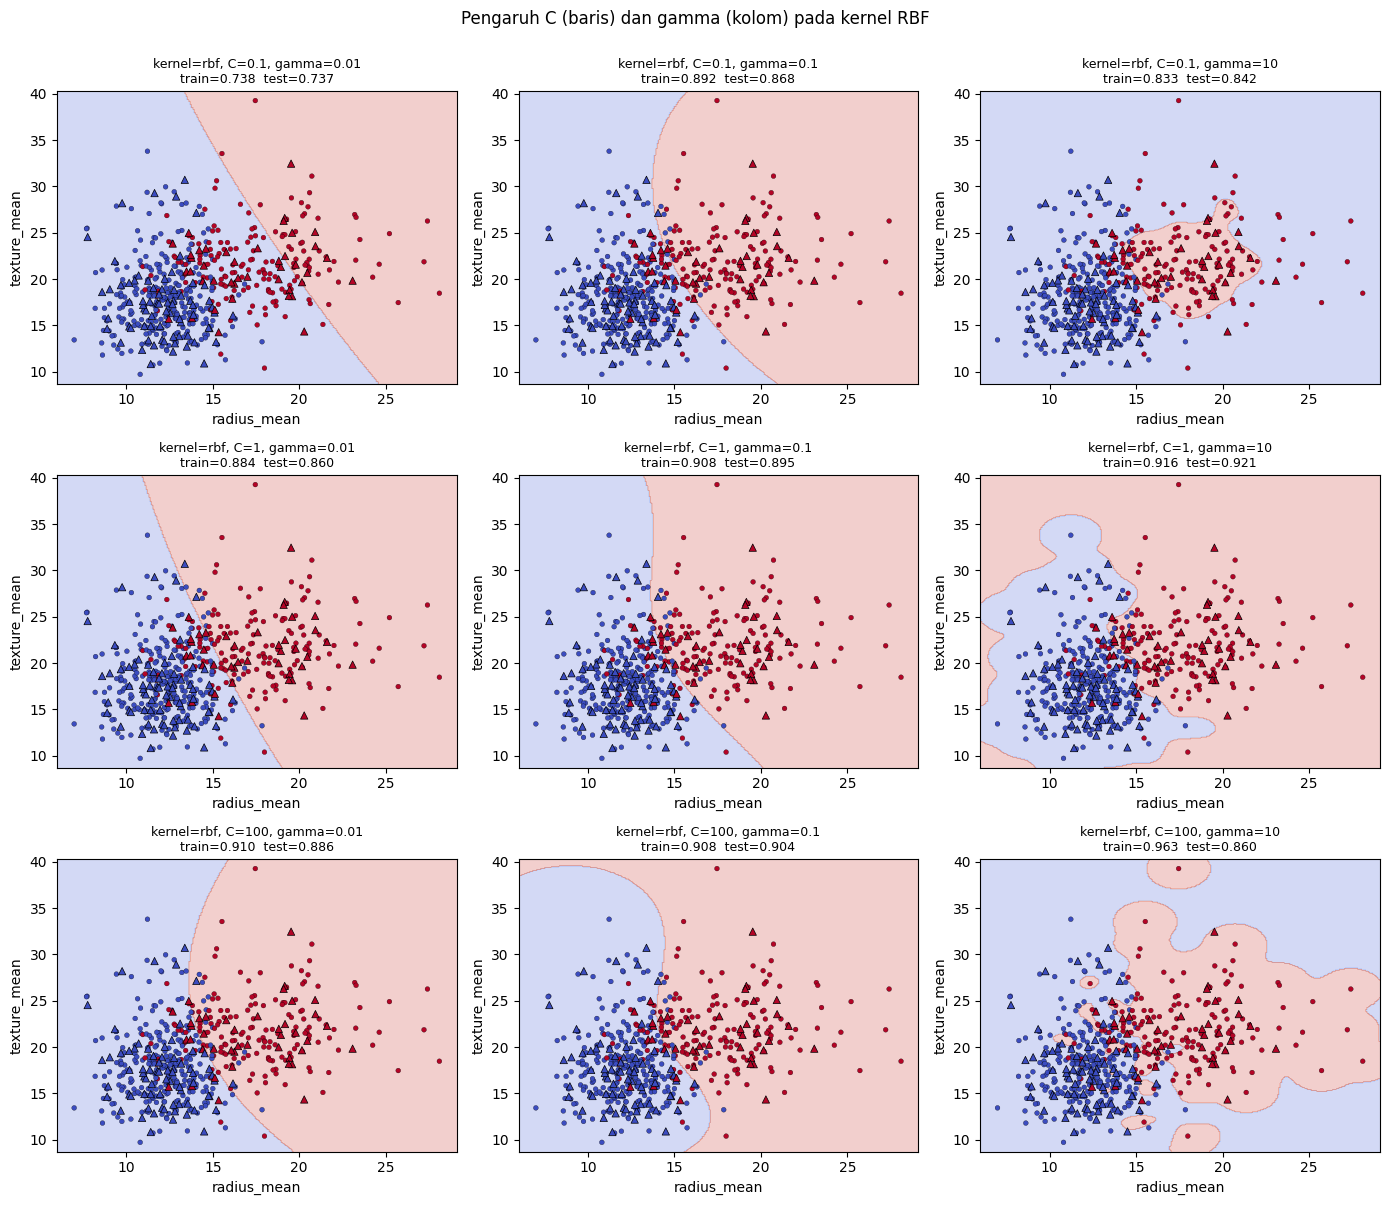

In [13]:
# (b) Pengaruh C dan gamma pada kernel RBF (baris = C, kolom = gamma)
Cs, gammas = [0.1, 1, 100], [0.01, 0.1, 10]
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, Cv in enumerate(Cs):
    for j, gv in enumerate(gammas):
        plot_boundary(axes[i, j], kernel="rbf", C=Cv, gamma=gv)
plt.suptitle("Pengaruh C (baris) dan gamma (kolom) pada kernel RBF", y=1.0)
plt.tight_layout(); plt.show()

#### Kesimpulan Praktikum 2

**Pengaruh kernel (C=1):**

| Kernel | Train | Test | Bentuk batas keputusan |
|---|---|---|---|
| linear | 0,892 | 0,868 | garis lurus |
| poly | 0,857 | 0,798 | lengkung halus, kurang pas pada data ini |
| rbf | 0,908 | 0,904 | lengkung fleksibel mengikuti sebaran kelas |

**Pengaruh C dan gamma (RBF), akurasi train / test:**

| C \ gamma | 0,01 | 0,1 | 10 |
|---|---|---|---|
| 0,1 | 0,738 / 0,737 | 0,892 / 0,868 | 0,833 / 0,842 |
| 1 | 0,884 / 0,860 | 0,908 / 0,895 | 0,916 / 0,921 |
| 100 | 0,910 / 0,886 | 0,908 / 0,904 | **0,963 / 0,860** |

- **gamma kecil (0,01) → batas terlalu halus (underfitting):** batasnya nyaris berupa garis lurus. Bila C juga kecil (C=0,1), garis itu bergeser ke kanan sehingga banyak titik ganas (merah) masuk wilayah jinak dan akurasi latih hanya 0,738.
- **gamma besar (10) + C besar (100) → overfitting:** train naik ke 0,963 tetapi test turun ke 0,860; terlihat dari batas yang bergerigi dan membentuk "pulau-pulau" kecil di sekitar titik latih.
- **C** mengatur ketegasan: C kecil membuat margin lebar dan toleran terhadap kesalahan (batas lebih sederhana), C besar memaksa klasifikasi benar pada data latih (batas lebih rumit).
- Kombinasi yang seimbang pada 2 fitur ini adalah **RBF dengan C=1–100 dan gamma=0,1** (test 0,895–0,904) atau C=1, gamma=10 (test 0,921). Akurasi hanya ±0,90 karena dua fitur saja tidak cukup memisahkan kelas; dengan 30 fitur pada Praktikum 8.5 akurasi mencapai 0,982.
- Catatan: test set hanya 114 sampel, sehingga selisih 1–2% (1–2 pasien) belum bermakna; pola yang konsisten adalah pola underfitting–overfitting dari kombinasi C dan gamma di atas.